<a href="https://colab.research.google.com/github/LeoRoma8/ISSD_PH/blob/main/PH2_PDF_EXTRACTOR_ROMANUTTI_LEONARDO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Instalación de librerías requeridas
!pip install pymupdf pdfplumber nltk matplotlib pandas requests -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 84.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 74.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [ ]:
import os
import requests
import fitz  # PyMuPDF

PDF_URL = "https://www.indec.gob.ar/uploads/informesdeprensa/ipc_10_268C45A9444C.pdf"
PDF_PATH = "indec_ipc_informe.pdf"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
}

response = requests.get(PDF_URL, headers=headers, stream=True, timeout=25)

if response.status_code == 200:
    with open(PDF_PATH, "wb") as f:
        for chunk in response.iter_content(chunk_size=8192):
            f.write(chunk)
    print(f"Descarga exitosa: {PDF_PATH} ({os.path.getsize(PDF_PATH) / 1024:.2f} KB)")
else:
    raise ConnectionError(f"Error al descargar: código HTTP {response.status_code}")

# Metadatos del documento
doc = fitz.open(PDF_PATH)
metadata = doc.metadata

print("\n" + "="*45)
print("METADATOS DEL DOCUMENTO (INDEC)")
print("="*45)
print(f"Título:               {metadata.get('title') or 'Informe Técnico IPC'}")
print(f"Autor:                {metadata.get('author') or 'INDEC Argentina'}")
print(f"Total de páginas:     {len(doc)}")
print(f"Software de creación: {metadata.get('creator') or metadata.get('producer')}")
print("="*45)

Descarga exitosa: indec_ipc_informe.pdf (4939.39 KB)

METADATOS DEL DOCUMENTO (INDEC)
Título:               Índice de precios al consumidor (IPC). Cobertura nacional. Septiembre de 2026
Autor:                Instituto Nacional de Estadística y Censos (INDEC)
Total de páginas:     20
Software de creación: Adobe InDesign 21.0 (Windows)


In [ ]:
# Función identificada: page.get_text("text") permite la extracción cruda estándar
# Para ver delimitadores exactos a nivel de bloques y líneas, se usa repr()

pagina_analisis = doc[4]  # Página 5 del documento
texto_crudo = pagina_analisis.get_text("text")

print("--- MUESTRA DEL TEXTO CRUDO (repr para ver caracteres de escape) ---")
print(repr(texto_crudo[:600]))

# Detección programática de caracteres separadores
separadores = {
    "Saltos de línea (\\n)": texto_crudo.count('\n'),
    "Retornos de carro (\\r)": texto_crudo.count('\r'),
    "Tabulaciones (\\t)": texto_crudo.count('\t'),
    "Doble salto (párrafos \\n\\n)": texto_crudo.count('\n\n'),
    "Espacios dobles ('  ')": texto_crudo.count('  ')
}

print("\n--- FRECUENCIA DE SEPARADORES EN LA PÁGINA ---")
for k, v in separadores.items():
    print(f"{k}: {v}")

--- MUESTRA DEL TEXTO CRUDO (repr para ver caracteres de escape) ---
'5/20\nÍndice de precios al consumidor. Septiembre de 2026\nBuenos Aires, 13 de octubre de 2026\nÍndices de precios\nÍndice de precios al consumidor\nSeptiembre de 2026\nPorcentaje\nNivel general\n1,9\n2,0\n2,0\n1,7\n1,9\n1,9\n1,4\nAlimentos y bebidas no alcohólicas\n2,0\n2,2\n2,0\n1,2\n1,4\n1,7\n1,7\nBebidas alcohólicas y tabaco\n1,4\n1,5\n1,3\n1,0\n1,1\n1,4\n1,6\nPrendas de vestir y calzado\n1,4\n1,9\n0,7\n0,4\n2,1\n2,3\n0,0\nVivienda, agua, electricidad, gas y otros \ncombustibles\n3,1\n2,7\n3,8\n4,1\n3,3\n2,6\n2,1\nEquipamiento y mantenimiento del hogar\n1,6\n1,7\n1,7\n1,6\n1,9\n1,5\n0,7\nSalud\n2,4\n2,4\n2,4\n2,1\n2,6\n2,2\n2,1\nTransporte\n1,5\n1,7\n1,5\n'

--- FRECUENCIA DE SEPARADORES EN LA PÁGINA ---
Saltos de línea (\n): 129
Retornos de carro (\r): 0
Tabulaciones (\t): 0
Doble salto (párrafos \n\n): 0
Espacios dobles ('  '): 1


Conclusión del análisis de separadores:
Los valores obtenidos (\t = 0, \n\n = 0 y \n = 129) son característicos de una página con alta densidad tabular. El formato PDF no implementa estructuras de grilla nativas, sino renderizado posicional por coordenadas (Los elementos son puestos en el cuerpo del PDF mediante coordenadas x,y). En consecuencia, la extracción de texto crudo linealiza la tabla descomponiendo cada celda numérica y encabezado en una secuencia vertical delimitada por saltos de línea individuales (\n), lo que imposibilita la reconstrucción de la matriz de datos sin librerías orientadas a la geometría de la página, por este motivo opte por utilizar pdf plumber.

In [ ]:
import pdfplumber
import pandas as pd

# Abrir el PDF con pdfplumber para extraer la estructura tabular
with pdfplumber.open(PDF_PATH) as pdf:
    # La página 20 corresponde al índice 19 (base cero)
    pagina_17 = pdf.pages[16]

    # Extraer las tablas de la página
    tablas = pagina_17.extract_tables()

print(f"Tablas encontradas en la página 17: {len(tablas)}")

if tablas:
    # Tomamos la primera tabla detectada
    tabla_cruda = tablas[0]

    # Convertir a DataFrame de Pandas
    df = pd.DataFrame(tabla_cruda)

    print("\n--- TABLA EXTRAÍDA SIN PROCESAR (Primeras filas) ---")
    print(df.head(10))

    # Limpieza básica: Eliminar filas completamente vacías o con puros elementos None
    df_limpio = df.dropna(how='all')

    # Intentar definir los encabezados de columna si la primera fila tiene datos válidos
    if not df_limpio.empty:
        # Asignar la primera fila válida como nombres de columnas
        nuevas_columnas = df_limpio.iloc[0].tolist()
        # Reemplazar None o celdas vacías en los encabezados por nombres genéricos
        nuevas_columnas = [col if col else f"Columna_{i}" for i, col in enumerate(nuevas_columnas)]
        df_limpio.columns = nuevas_columnas

        # Descartar la fila que se usó como encabezado
        df_limpio = df_limpio.iloc[1:].reset_index(drop=True)

        # Quitar saltos de línea dentro de los textos de las celdas
        df_limpio = df_limpio.applymap(lambda x: x.replace('\n', ' ') if isinstance(x, str) else x)

        print("\n--- DATAFRAME LIMPIO Y PROCESADO ---")
        print(df_limpio)
else:
    print("No se detectaron tablas automáticas en la página 17. Se sugiere revisar la configuración de detección de bordes.")

Tablas encontradas en la página 17: 1

--- TABLA EXTRAÍDA SIN PROCESAR (Primeras filas) ---
                                    0                           1         2  \
0               Principales aperturas  Región geográfica del país      None   
1                                None                         GBA  Pampeana   
2                                                      Porcentaje      None   
3                       Nivel general                        33,5      33,1   
4  Alimentos y bebidas no alcohólicas                        34,6      35,3   
5                           Alimentos                        35,4      36,2   
6                      Pan y cereales                        27,9      24,3   
7                  Carnes y derivados                        42,5      43,8   
8   Leche, productos lácteos y huevos                        22,4      21,8   
9           Aceites, grasas y manteca                        32,6      29,1   

         3         4     5          6 

/tmp/ipykernel_1952/1704237773.py:39: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_limpio = df_limpio.applymap(lambda x: x.replace('\n', ' ') if isinstance(x, str) else x)


In [ ]:
import pandas as pd

# 1. Crear el DataFrame a partir de la lista de datos extraídos (tabla_cruda)
df_nuevo = pd.DataFrame(tabla_cruda)

# 2. Definir los nombres de las columnas (usando la fila de regiones)
nombres_columnas = ['Aperturas', 'GBA', 'Pampeana', 'Noreste', 'Noroeste', 'Cuyo', 'Patagonia']
df_nuevo.columns = nombres_columnas

# 3. Eliminar las filas de encabezado iniciales innecesarias (filas 0, 1 y 2)
df_nuevo = df_nuevo.iloc[3:].reset_index(drop=True)

# 4. Limpieza: Eliminar saltos de línea de la primera columna si existen
df_nuevo['Aperturas'] = df_nuevo['Aperturas'].str.replace('\n', ' ', regex=False)

# Mostrar el resultado final estructurado
display(df_nuevo.head(10))

,Aperturas,GBA,Pampeana,Noreste,Noroeste,Cuyo,Patagonia
0,Nivel general,"33,5","33,1","36,9","33,6","33,0","30,3"
1,Alimentos y bebidas no alcohólicas,"34,6","35,3","40,8","36,8","34,7","29,8"
2,Alimentos,"35,4","36,2","42,5","38,2","35,8","30,2"
3,Pan y cereales,"27,9","24,3","21,7","22,4","25,8","21,9"
4,Carnes y derivados,"42,5","43,8","50,7","44,5","39,3","33,5"
5,"Leche, productos lácteos y huevos","22,4","21,8","22,2","16,4","17,1","20,4"
6,"Aceites, grasas y manteca","32,6","29,1","38,3","33,8","29,5","28,3"
7,Frutas,"25,1","30,2","37,5","34,8","22,5","30,1"
8,"Verduras, tubérculos y legumbres","54,1","59,1","78,5","76,2","75,8","49,5"
9,"Azúcar, dulces, chocolate, golosinas, etc.","34,8","29,9","37,3","32,0","30,4","29,9"


In [ ]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import string
from collections import Counter
import pandas as pd
import plotly.express as px
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Descargar recursos necesarios de NLTK (incluyendo 'punkt_tab')
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

# Extraer el texto de la página 18 (índice 17)
pagina_18 = doc[17]
texto_pagina = pagina_18.get_text("text")

# 1. Tokenización y conversión a minúsculas
tokens = word_tokenize(texto_pagina.lower())

# 2. Limpieza de stopwords y signos de puntuación
stop_words_es = set(stopwords.words('spanish'))

# Añadimos stopwords personalizadas e incluimos conectores y prefijos geográficos como 'san' o 'santa'
stop_words_es.update([
    'septiembre', '2026', 'índice', 'precios', 'consumidor', 'porcentaje',
    'cuadro', 'gráfico', 'página', 'nacional', 'región', 'cobertura',
    'san', 'santa', 'río', 'rio', 'gran', 'aires', 'buenos', 'breve', 'nota'
])

puntuacion = set(string.punctuation) | {'“', '”', '...', '..', '•', '–'}

tokens_limpios = [token for token in tokens if token not in stop_words_es and token not in puntuacion and token.isalpha()]

# Obtener frecuencia de palabras
frecuencia_palabras = Counter(tokens_limpios)
top_15_palabras = frecuencia_palabras.most_common(15)

# Crear DataFrame para el gráfico
df_frecuencias = pd.DataFrame(top_15_palabras, columns=['Palabra', 'Frecuencia'])
# Ordenar para que las barras más largas queden arriba en el gráfico horizontal
df_frecuencias = df_frecuencias.sort_values(by='Frecuencia', ascending=True)

print("Top 15 palabras más frecuentes extraídas (sin prefijos geográficos):")
display(df_frecuencias.sort_values(by='Frecuencia', ascending=False))

Top 15 palabras más frecuentes extraídas (sin prefijos geográficos):


,Palabra,Frecuencia
0,ipc,6
5,índices,3
3,hogares,3
6,partir,3
4,resultados,3
2,consumo,3
1,argentina,3
9,servicios,2
10,gasto,2
11,total,2


In [ ]:
# 3. Gráfico de barras horizontales con Plotly Express
fig_barras = px.bar(
    df_frecuencias,
    x='Frecuencia',
    y='Palabra',
    orientation='h',
    title='Top 15 Palabras Más Frecuentes (Pág. 18 - Informe IPC)',
    labels={'Frecuencia': 'Cantidad de Apariciones', 'Palabra': 'Palabras'},
    color='Frecuencia',
    color_continuous_scale='Viridis'
)

fig_barras.update_layout(
    yaxis_ticksuffix=' ',
    template='plotly_white',
    width=800,
    height=500
)

fig_barras.show()

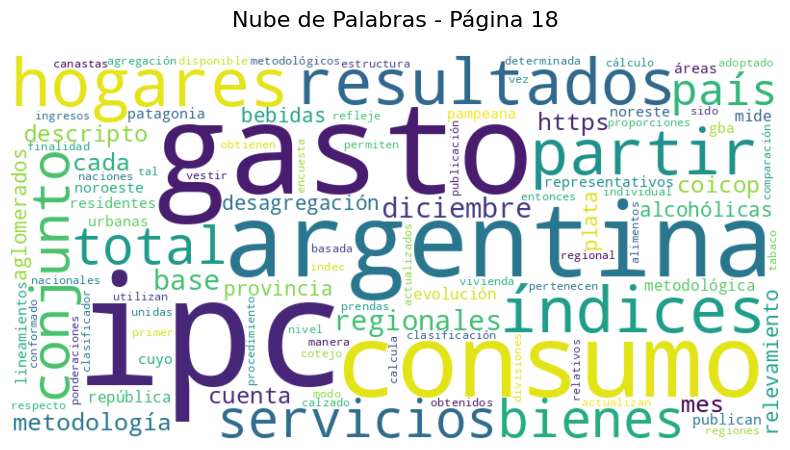

In [ ]:
# 4. Generación de la Nube de Palabras
texto_para_nube = " ".join(tokens_limpios)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='viridis',
    max_words=100
).generate(texto_para_nube)

# Visualización de la Nube de Palabras
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Nube de Palabras - Página 18', fontsize=16, pad=20)
plt.show()

Efectivamente, la primera pasada que le di al codigo, la palabra principal que el algoritmo habia extraido fue la palbra "san" que formaba parte de los nombres de las provincias de nuestro pais. Para evitar esto. Me apoye en Geminiy me indico que podiamos crear una lista de palabras personalizadas para que sean consideradas stop words y efectivamente al reprocesar las celdas se obtuvo un resultado mas coherente.

Objetivos
Automatizar la descarga de fuentes documentales externas.

Explorar la estructura técnica y el contenido de un archivo PDF.

Aplicar técnicas de limpieza de texto (NLP) para análisis estadístico.

Consignas de resolución
El trabajo debe entregarse en formato Jupyter Notebook (.ipynb), asegurando que todas las celdas sean ejecutables y estén debidamente comentadas.

1. Adquisición y metadatos
Descarga: Utilizando las librerías requests o urllib, descarga un archivo PDF desde un enlace público (por ejemplo, un artículo científico de arXiv o un reporte institucional).

No puede usar el mismo pdf o enlace que otra persona ya haya presentado en el foro. El PDF elegido debe contener texto extraible, no deben ser páginas escaneadas tipo imagen.

Inspección: Muestra por pantalla los metadatos del archivo: título, autor, número de páginas y software de creación.

Sugerencia: Puedes utilizar librerías como PyMuPDF (fitz) o PyPDF2.

2. Análisis estructural del texto
Extracción cruda: Extrae el texto del PDF.. Identifica la función de la librería elegida que te ayuda en esta tarea y te permite ver el texto extraído lo más crudo posible.

Análisis de separadores: Observa y describe cómo están separados los párrafos, las secciones y los capítulos.

Identificación de caracteres: ¿Qué caracteres especiales funcionan como separadores de línea o de bloque en este archivo específico? (Ej: \n, \r, \t o secuencias de espacios).

3. Extracción de datos tabulares
Busca una página en el PDF que contenga una tabla de datos.

Extrae dicha tabla y conviértela en un DataFrame de Pandas.

Realiza una limpieza básica de la tabla (nombrar columnas, eliminar filas vacías).

Sugerencia: Se recomienda el uso de pdfplumber o tabula-py.

4. Análisis de frecuencias (NLP básico)
Elige una página que contenga únicamente texto narrativo, usa la biblioteca nltk o spacy  y realiza lo siguiente:

Tokenización: Extrae el texto y conviértelo a minúsculas.

Limpieza: Elimina las stop words (palabras funcionales sin peso semántico como "el", "de", "y") y signos de puntuación.

Visualización: Genera un gráfico de barras que muestre las 15 palabras más frecuentes en esa página. ¿ Te surgieron en esta visualización tokens que también considerarías stop words? Comenta y justifica.